# Full Dataset EDA — Big-Vul

This notebook explores the **complete** Big-Vul dataset (`data/bigvul.csv`) to understand CVE/CWE coverage and data distribution before expanding the POC beyond CWE-119.

**Prerequisite:** Run `dvc repro data_ingestion` to download `data/bigvul.csv` if it does not exist.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from graph_vul.config import BIGVUL_CSV
from graph_vul.pipeline.extract_subset import _read_bigvul_csv

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
# Load the full Big-Vul dataset (handles ZIP-compressed files)
df = _read_bigvul_csv(str(BIGVUL_CSV))

# Verify expected columns exist
required_cols = {"func_before", "cve_id", "vul"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}. Available: {list(df.columns)}")

print(f"Loaded {len(df):,} rows, {len(df.columns)} columns")
print(f"\nColumns: {list(df.columns)}")

Loaded 188,636 rows, 36 columns

Columns: ['Unnamed: 0', 'Access Gained', 'Attack Origin', 'Authentication Required', 'Availability', 'cve_id', 'CVE Page', 'cwe_id', 'Complexity', 'Confidentiality', 'Integrity', 'Known Exploits', 'Publish Date', 'Score', 'cve_desc', 'Update Date', 'Vulnerability Classification', 'add_lines', 'codeLink', 'commit_id', 'commit_message', 'del_lines', 'file_name', 'files_changed', 'func_after', 'func_before', 'lang', 'lines_after', 'lines_before', 'parentID', 'patch', 'project', 'project_after', 'project_before', 'vul', 'vul_func_with_fix']


/Users/noamc/repos/graph-vul/graph_vul/pipeline/extract_subset.py:19: DtypeWarning: Columns (1,20,22,23,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(src, compression="zip")


## 1. Dataset Overview

In [3]:
print(f"Total samples: {len(df):,}")
print(f"\nClass distribution:")
counts = df["vul"].value_counts()
for label, count in sorted(counts.items()):
    name = "vulnerable" if label == 1 else "benign"
    print(f"  {name} ({label}): {count:,} ({count / len(df) * 100:.1f}%)")

print(f"\nUnique CVE IDs: {df['cve_id'].nunique():,}")
if "cwe_id" in df.columns:
    print(f"Unique CWE IDs: {df['cwe_id'].nunique():,}")

Total samples: 188,636

Class distribution:
  benign (0): 177,736 (94.2%)
  vulnerable (1): 10,900 (5.8%)

Unique CVE IDs: 3,539
Unique CWE IDs: 91


In [4]:
df.head()

,Unnamed: 0,Access Gained,Attack Origin,Authentication Required,Availability,cve_id,CVE Page,cwe_id,Complexity,Confidentiality,...,lang,lines_after,lines_before,parentID,patch,project,project_after,project_before,vul,vul_func_with_fix
0,0,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static bool check_rodc_critical_attribute(stru...
1,1,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_entry(struct samldb_ctx ...
2,2,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_entry_callback(struct ld...
3,3,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_handle_msDS_IntId(struct...
4,4,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_step(struct samldb_ctx *...


## 2. CVE Distribution

Unique CVEs: 3,539

Samples per CVE:
count    3539.000000
mean       49.504380
std        95.066557
min         1.000000
25%         7.000000
50%        22.000000
75%        54.000000
max      1520.000000


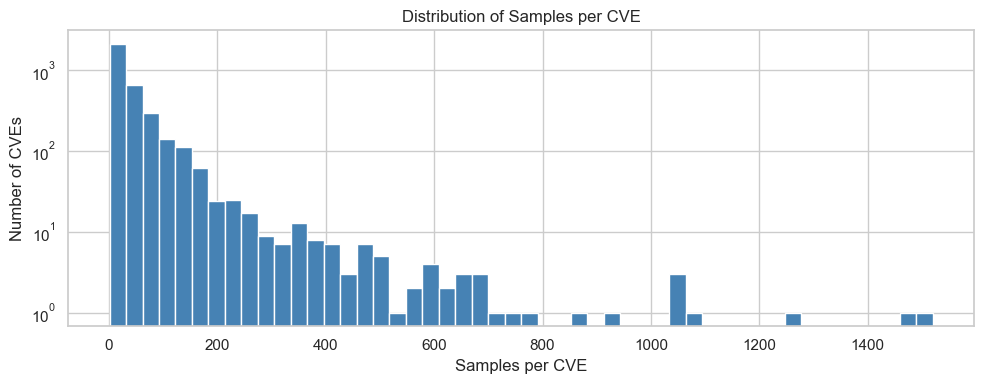

In [5]:
cve_counts = df.groupby("cve_id").agg(
    total=("vul", "count"),
    vulnerable=("vul", "sum"),
).reset_index()
cve_counts["benign"] = cve_counts["total"] - cve_counts["vulnerable"]
cve_counts["vul_ratio"] = cve_counts["vulnerable"] / cve_counts["total"]

print(f"Unique CVEs: {len(cve_counts):,}")
print(f"\nSamples per CVE:")
print(cve_counts["total"].describe().to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cve_counts["total"], bins=50, color="steelblue", edgecolor="white")
ax.set_title("Distribution of Samples per CVE")
ax.set_xlabel("Samples per CVE")
ax.set_ylabel("Number of CVEs")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

In [6]:
# Top 30 CVEs by sample count
top30_cves = cve_counts.nlargest(30, "total")[["cve_id", "total", "vulnerable", "benign", "vul_ratio"]].reset_index(drop=True)
top30_cves["vul_ratio"] = top30_cves["vul_ratio"].map("{:.1%}".format)
top30_cves

,cve_id,total,vulnerable,benign,vul_ratio
0,CVE-2016-5219,1520,12,1508,0.8%
1,CVE-2014-1713,1462,8,1454,0.5%
2,CVE-2011-2918,1259,74,1185,5.9%
3,CVE-2017-5120,1066,2,1064,0.2%
4,CVE-2012-2875,1057,28,1029,2.6%
5,CVE-2012-5148,1053,20,1033,1.9%
6,CVE-2013-7421,1049,1,1048,0.1%
7,CVE-2018-13006,931,6,925,0.6%
8,CVE-2017-9059,877,51,826,5.8%
9,CVE-2017-5019,768,7,761,0.9%


## 3. CWE Distribution

In [7]:
if "cwe_id" not in df.columns:
    print("CWE ID column not found — skipping CWE analysis")
else:
    cwe_counts = df.groupby("cwe_id").agg(
        total=("vul", "count"),
        vulnerable=("vul", "sum"),
    ).reset_index()
    cwe_counts["benign"] = cwe_counts["total"] - cwe_counts["vulnerable"]
    cwe_counts["vul_ratio"] = cwe_counts["vulnerable"] / cwe_counts["total"]
    cwe_counts = cwe_counts.sort_values("total", ascending=False).reset_index(drop=True)

    print(f"Unique CWEs: {len(cwe_counts):,}")
    print(f"\nSamples per CWE:")
    print(cwe_counts["total"].describe().to_string())

Unique CWEs: 91

Samples per CWE:
count       91.000000
mean      1675.065934
std       4260.617949
min          1.000000
25%         38.000000
50%         89.000000
75%        912.000000
max      26497.000000


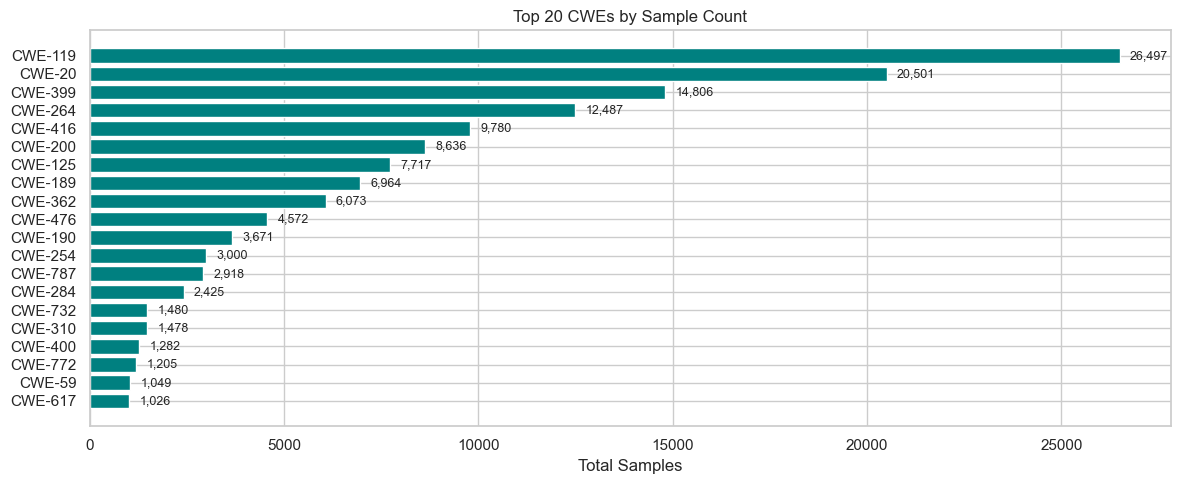

In [8]:
# Top 20 CWEs by sample count — bar chart
top20_cwes = cwe_counts.head(20)

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(top20_cwes["cwe_id"].iloc[::-1], top20_cwes["total"].iloc[::-1], color="teal")
ax.set_title("Top 20 CWEs by Sample Count")
ax.set_xlabel("Total Samples")
for i, (cwe, total) in enumerate(zip(top20_cwes["cwe_id"].iloc[::-1], top20_cwes["total"].iloc[::-1])):
    ax.text(total + max(top20_cwes["total"]) * 0.01, i, f"{total:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
# Table: top 20 CWEs with class balance
top20_table = top20_cwes[["cwe_id", "total", "vulnerable", "benign", "vul_ratio"]].copy().reset_index(drop=True)
top20_table["vul_ratio"] = top20_table["vul_ratio"].map("{:.1%}".format)
top20_table

,cwe_id,total,vulnerable,benign,vul_ratio
0,CWE-119,26497,2127,24370,8.0%
1,CWE-20,20501,1142,19359,5.6%
2,CWE-399,14806,736,14070,5.0%
3,CWE-264,12487,508,11979,4.1%
4,CWE-416,9780,330,9450,3.4%
5,CWE-200,8636,503,8133,5.8%
6,CWE-125,7717,625,7092,8.1%
7,CWE-189,6964,337,6627,4.8%
8,CWE-362,6073,278,5795,4.6%
9,CWE-476,4572,215,4357,4.7%


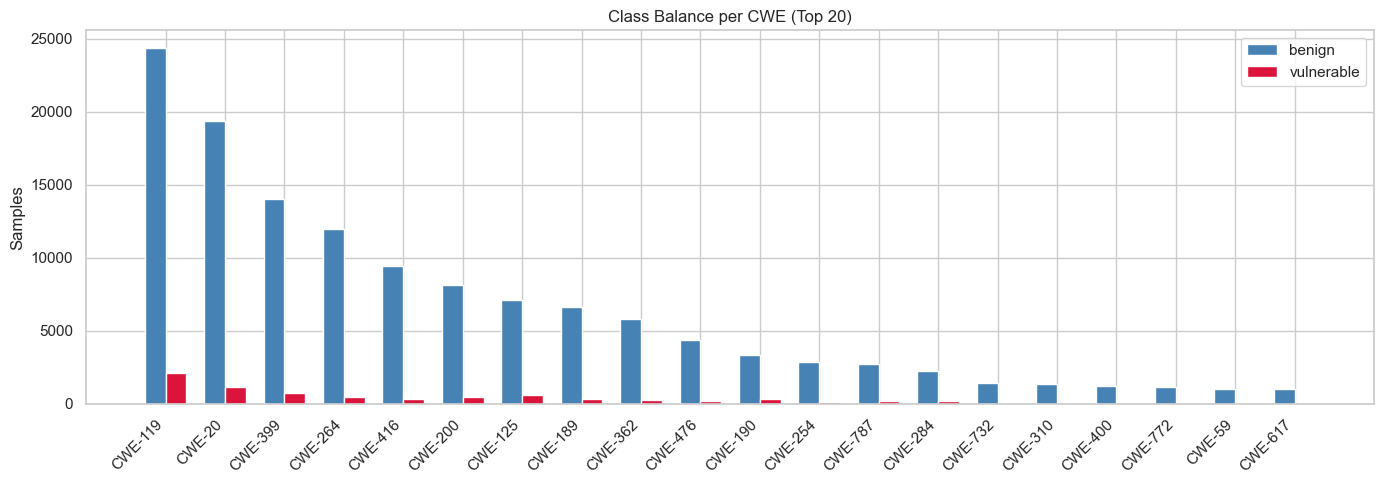

In [10]:
# Grouped bar chart: vulnerable vs benign for top 20 CWEs
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(top20_cwes))
width = 0.35
ax.bar(x - width / 2, top20_cwes["benign"].values, width, label="benign", color="steelblue")
ax.bar(x + width / 2, top20_cwes["vulnerable"].values, width, label="vulnerable", color="crimson")
ax.set_xticks(x)
ax.set_xticklabels(top20_cwes["cwe_id"].values, rotation=45, ha="right")
ax.set_ylabel("Samples")
ax.set_title("Class Balance per CWE (Top 20)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Code Length Statistics

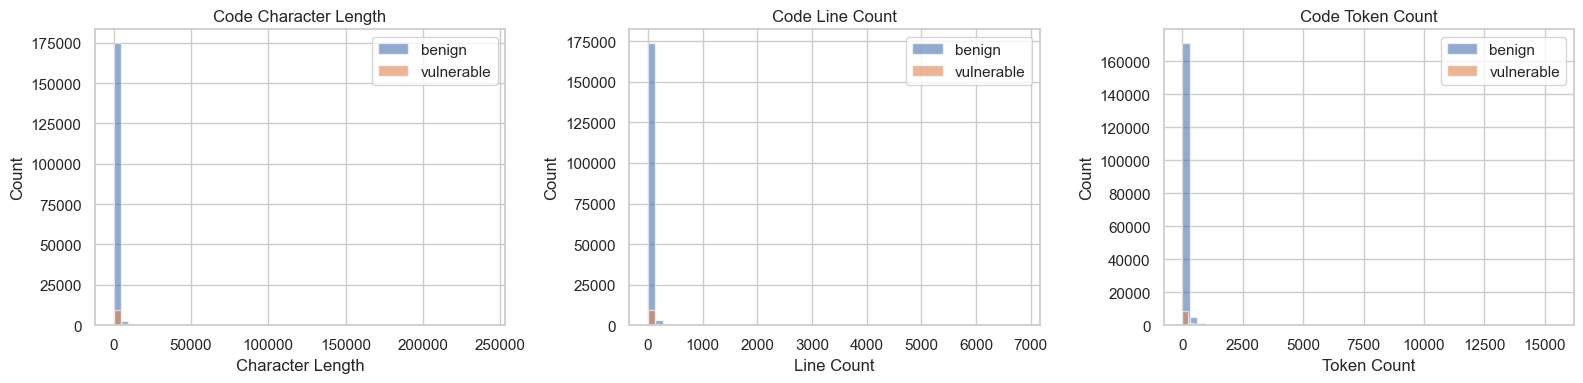

,code_char_len,code_line_count,code_token_count
count,188636.000000,188636.000000,188636.000000
mean,910.437371,30.934069,83.485215
std,2504.872643,76.167640,211.857585
min,14.000000,2.000000,2.000000
25%,193.000000,7.000000,15.000000
50%,395.000000,14.000000,33.000000
75%,873.000000,31.000000,80.000000
max,240969.000000,6820.000000,15441.000000


In [11]:
code = df["func_before"].dropna()
df["code_char_len"] = df["func_before"].str.len()
df["code_line_count"] = df["func_before"].str.count("\n") + 1
df["code_token_count"] = df["func_before"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
    axes,
    ["code_char_len", "code_line_count", "code_token_count"],
    ["Character Length", "Line Count", "Token Count"],
):
    for label, group in df.groupby("vul"):
        name = "vulnerable" if label == 1 else "benign"
        ax.hist(group[col].dropna(), bins=50, alpha=0.6, label=name)
    ax.set_title(f"Code {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Count")
    ax.legend()
plt.tight_layout()
plt.show()

df[["code_char_len", "code_line_count", "code_token_count"]].describe()

## 5. CVE Description Statistics

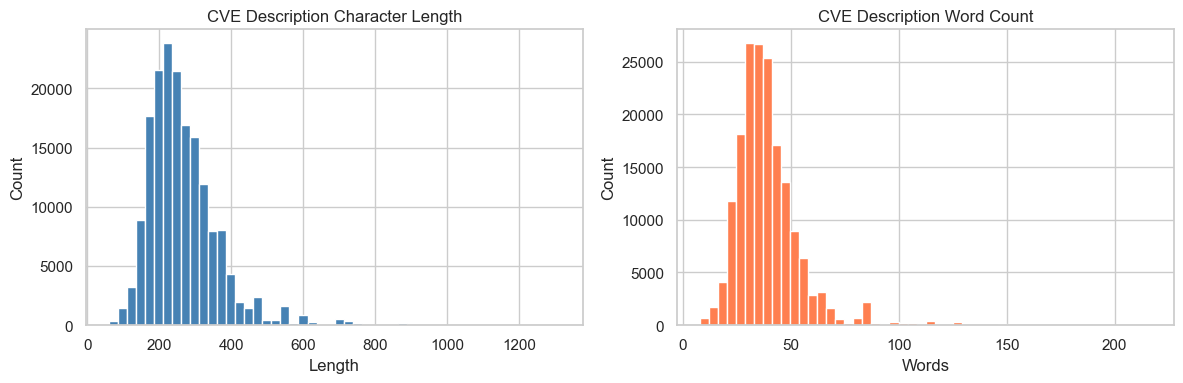

,desc_char_len,desc_word_count
count,174614.000000,174614.000000
mean,266.235926,39.257688
std,99.708812,15.205955
min,60.000000,8.000000
25%,202.000000,30.000000
50%,247.000000,37.000000
75%,309.000000,45.000000
max,1315.000000,217.000000


In [12]:
desc_col = "cve_desc" if "cve_desc" in df.columns else "Summary"
df["desc_char_len"] = df[desc_col].str.len()
df["desc_word_count"] = df[desc_col].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["desc_char_len"].dropna(), bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("CVE Description Character Length")
axes[0].set_xlabel("Length")
axes[0].set_ylabel("Count")

axes[1].hist(df["desc_word_count"].dropna(), bins=50, color="coral", edgecolor="white")
axes[1].set_title("CVE Description Word Count")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

df[["desc_char_len", "desc_word_count"]].describe()

## 6. Expansion Candidate Recommendations

CWEs with at least 200 vulnerable samples and at least 30% benign representation are candidates for POC expansion.

In [13]:
MIN_VUL_SAMPLES = 200
MIN_BENIGN_RATIO = 0.30

candidates = cwe_counts[
    (cwe_counts["vulnerable"] >= MIN_VUL_SAMPLES)
    & (cwe_counts["benign"] / cwe_counts["total"] >= MIN_BENIGN_RATIO)
].copy()
candidates["benign_ratio"] = (candidates["benign"] / candidates["total"]).map("{:.1%}".format)
candidates = candidates.sort_values("total", ascending=False).reset_index(drop=True)

display_cols = ["cwe_id", "total", "vulnerable", "benign", "benign_ratio"]
print(f"Found {len(candidates)} candidate CWEs for expansion (>={MIN_VUL_SAMPLES} vulnerable, >={MIN_BENIGN_RATIO:.0%} benign):\n")
candidates[display_cols]

Found 11 candidate CWEs for expansion (>=200 vulnerable, >=30% benign):



,cwe_id,total,vulnerable,benign,benign_ratio
0,CWE-119,26497,2127,24370,92.0%
1,CWE-20,20501,1142,19359,94.4%
2,CWE-399,14806,736,14070,95.0%
3,CWE-264,12487,508,11979,95.9%
4,CWE-416,9780,330,9450,96.6%
5,CWE-200,8636,503,8133,94.2%
6,CWE-125,7717,625,7092,91.9%
7,CWE-189,6964,337,6627,95.2%
8,CWE-362,6073,278,5795,95.4%
9,CWE-476,4572,215,4357,95.3%


## 7. Sampling and Split Design EDA

The current pipeline samples 1,000 rows **randomly** from the full Big-Vul dataset and splits them row-level into train/val/test. This section analyses the dataset structure to design:

1. A **smarter 1,000-row sampling strategy** that improves CVE/CWE diversity and class balance.
2. A **leakage-aware split strategy** that prevents the same CVE, commit, or duplicated code from appearing in multiple splits.

In [14]:
# ── Helper functions for Section 7 ──────────────────────────────────────────

SEED = 42

def _has(col):
    """Check if a column exists in df."""
    return col in df.columns

def summarize_group_sizes(series, name):
    """Print summary stats for a grouping column and return top-20 groups."""
    grp = series.value_counts()
    stats = grp.describe()
    print(f"\n{'='*50}")
    print(f"  {name}: {len(grp):,} unique groups")
    print(f"  samples/group — mean={grp.mean():.1f}  median={grp.median():.0f}  "
          f"std={grp.std():.1f}  min={grp.min()}  max={grp.max()}")
    top20 = grp.head(20).reset_index()
    top20.columns = [name, "count"]
    return top20

def compute_group_label_balance(group_col, label_col="vul"):
    """Compute per-group label balance. Returns a DataFrame."""
    if not (_has(group_col) and _has(label_col)):
        print(f"  ⏭ Skipping — missing column(s): {group_col} or {label_col}")
        return None
    g = df.groupby(group_col)[label_col].agg(["count", "sum"])
    g.columns = ["total", "vulnerable"]
    g["benign"] = g["total"] - g["vulnerable"]
    g["vul_ratio"] = g["vulnerable"] / g["total"]
    return g.reset_index()

# ── Sampling strategies ─────────────────────────────────────────────────────

def sample_random(df_in, n=1000):
    return df_in.sample(n=min(n, len(df_in)), random_state=SEED)

def sample_stratified_vul(df_in, n=1000):
    """Stratified by vul label, preserving original ratio."""
    if not _has("vul"):
        return sample_random(df_in, n)
    frac = n / len(df_in)
    return df_in.groupby("vul", group_keys=False).apply(
        lambda x: x.sample(n=max(1, int(len(x) * frac)), random_state=SEED)
    ).head(n)

def sample_capped_per_group(df_in, group_col, cap=10, n=1000):
    """Cap max rows per group, then downsample to n."""
    if not _has(group_col):
        print(f"  ⏭ Cannot cap by {group_col} — column missing")
        return None
    capped = df_in.groupby(group_col, group_keys=False).apply(
        lambda x: x.sample(n=min(len(x), cap), random_state=SEED)
    )
    if len(capped) > n:
        capped = capped.sample(n=n, random_state=SEED)
    return capped

def sample_hierarchical(df_in, n=1000):
    """Sample CWEs → CVEs within CWE → rows within CVE."""
    if not (_has("cwe_id") and _has("cve_id")):
        print("  ⏭ Hierarchical sampler needs cwe_id and cve_id")
        return None
    rng = np.random.RandomState(SEED)
    cwes = df_in["cwe_id"].unique()
    rng.shuffle(cwes)
    budget = n
    rows = []
    per_cwe = max(1, n // len(cwes))
    for cwe in cwes:
        if budget <= 0:
            break
        cwe_df = df_in[df_in["cwe_id"] == cwe]
        cves = cwe_df["cve_id"].unique()
        rng.shuffle(cves)
        per_cve = max(1, min(per_cwe, budget) // max(len(cves), 1))
        for cve in cves:
            if budget <= 0:
                break
            cve_df = cwe_df[cwe_df["cve_id"] == cve]
            take = min(len(cve_df), per_cve, budget)
            rows.append(cve_df.sample(n=take, random_state=SEED))
            budget -= take
    result = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    # fill remaining budget with random rows not yet sampled
    if len(result) < n:
        remaining = df_in.drop(result.index, errors="ignore")
        fill = min(n - len(result), len(remaining))
        if fill > 0:
            result = pd.concat([result, remaining.sample(n=fill, random_state=SEED)], ignore_index=True)
    return result.head(n)

def sample_balanced_diversity(df_in, n=1000, cve_cap=5):
    """50/50 vul balance + capped CVE diversity."""
    if not (_has("vul") and _has("cve_id")):
        print("  ⏭ Balanced-diversity sampler needs vul and cve_id")
        return None
    half = n // 2
    vul = df_in[df_in["vul"] == 1]
    ben = df_in[df_in["vul"] == 0]
    # cap per CVE then sample
    vul_capped = vul.groupby("cve_id", group_keys=False).apply(
        lambda x: x.sample(n=min(len(x), cve_cap), random_state=SEED))
    ben_capped = ben.groupby("cve_id", group_keys=False).apply(
        lambda x: x.sample(n=min(len(x), cve_cap), random_state=SEED))
    vul_sample = vul_capped.sample(n=min(half, len(vul_capped)), random_state=SEED)
    ben_sample = ben_capped.sample(n=min(half, len(ben_capped)), random_state=SEED)
    return pd.concat([vul_sample, ben_sample], ignore_index=True).head(n)

# ── Evaluation helpers ──────────────────────────────────────────────────────

def evaluate_sample_diversity(sample_df, name="sample"):
    """Compute diversity metrics for a sample. Returns a dict."""
    m = {"strategy": name, "rows": len(sample_df)}
    m["vul_ratio"] = sample_df["vul"].mean() if _has("vul") else None
    for col in ["cve_id", "cwe_id", "project"]:
        if col in sample_df.columns:
            m[f"unique_{col}s"] = sample_df[col].nunique()
            grp = sample_df[col].value_counts()
            m[f"median_per_{col}"] = grp.median()
            m[f"max_per_{col}"] = grp.max()
        else:
            m[f"unique_{col}s"] = None
            m[f"median_per_{col}"] = None
            m[f"max_per_{col}"] = None
    if "code_char_len" in sample_df.columns:
        m["median_char_len"] = sample_df["code_char_len"].median()
        m["p95_char_len"] = sample_df["code_char_len"].quantile(0.95)
    return m

def simulate_group_split(df_in, group_col=None, train=0.8, val=0.1, test=0.1):
    """Simulate train/val/test split. If group_col is None, row-random split."""
    rng = np.random.RandomState(SEED)
    if group_col is None or group_col not in df_in.columns:
        idx = rng.permutation(len(df_in))
        n_train = int(len(df_in) * train)
        n_val = int(len(df_in) * val)
        splits = {
            "train": df_in.iloc[idx[:n_train]],
            "val": df_in.iloc[idx[n_train:n_train + n_val]],
            "test": df_in.iloc[idx[n_train + n_val:]],
        }
        return splits, "row-random"
    groups = df_in[group_col].unique()
    rng.shuffle(groups)
    n_train = int(len(groups) * train)
    n_val = int(len(groups) * val)
    train_groups = set(groups[:n_train])
    val_groups = set(groups[n_train:n_train + n_val])
    test_groups = set(groups[n_train + n_val:])
    splits = {
        "train": df_in[df_in[group_col].isin(train_groups)],
        "val": df_in[df_in[group_col].isin(val_groups)],
        "test": df_in[df_in[group_col].isin(test_groups)],
    }
    return splits, f"group-by-{group_col}"

print("✓ Helper functions defined.")

✓ Helper functions defined.


### 7.1 Group structure and potential leakage sources

**What this checks:** Which columns form natural groups in the dataset (CVE, CWE, project, commit, file) and how large/skewed those groups are.

**Why it matters:** If the same CVE or commit appears in both train and test, the model can memorise CVE-specific patterns instead of learning general vulnerability signals. Large groups amplify this risk.

In [15]:
# 7.1a — Column existence check and group-size summaries
candidate_cols = ["cve_id", "cwe_id", "project", "commit_id", "file_name", "func_before", "func_after"]
print("Column existence:")
for c in candidate_cols:
    print(f"  {c:15s} {'✓ present' if _has(c) else '✗ MISSING'}")

group_cols = ["cve_id", "cwe_id", "project", "commit_id", "file_name"]
top20_tables = {}
for col in group_cols:
    if _has(col):
        top20_tables[col] = summarize_group_sizes(df[col], col)

# Show top-20 for the three most important grouping columns
for col in ["cve_id", "cwe_id", "project"]:
    if col in top20_tables:
        print(f"\nTop 20 largest {col} groups:")
        display(top20_tables[col])

Column existence:
  cve_id          ✓ present
  cwe_id          ✓ present
  project         ✓ present
  commit_id       ✓ present
  file_name       ✓ present
  func_before     ✓ present
  func_after      ✓ present

  cve_id: 3,539 unique groups
  samples/group — mean=49.5  median=22  std=95.1  min=1  max=1520

  cwe_id: 91 unique groups
  samples/group — mean=1675.1  median=89  std=4260.6  min=1  max=26497

  project: 310 unique groups
  samples/group — mean=608.5  median=52  std=5141.9  min=1  max=77173

  commit_id: 4,058 unique groups
  samples/group — mean=46.5  median=20  std=88.3  min=1  max=1520

  file_name: 4,451 unique groups
  samples/group — mean=38.1  median=18  std=78.4  min=1  max=1915

Top 20 largest cve_id groups:


,cve_id,count
0,CVE-2016-5219,1520
1,CVE-2014-1713,1462
2,CVE-2011-2918,1259
3,CVE-2017-5120,1066
4,CVE-2012-2875,1057
5,CVE-2012-5148,1053
6,CVE-2013-7421,1049
7,CVE-2018-13006,931
8,CVE-2017-9059,877
9,CVE-2017-5019,768



Top 20 largest cwe_id groups:


,cwe_id,count
0,CWE-119,26497
1,CWE-20,20501
2,CWE-399,14806
3,CWE-264,12487
4,CWE-416,9780
5,CWE-200,8636
6,CWE-125,7717
7,CWE-189,6964
8,CWE-362,6073
9,CWE-476,4572



Top 20 largest project groups:


,project,count
0,Chrome,77173
1,linux,46855
2,Android,8691
3,qemu,3096
4,php,2709
5,ImageMagick,2520
6,savannah,2176
7,FFmpeg,1932
8,ghostscript,1867
9,openssl,1860


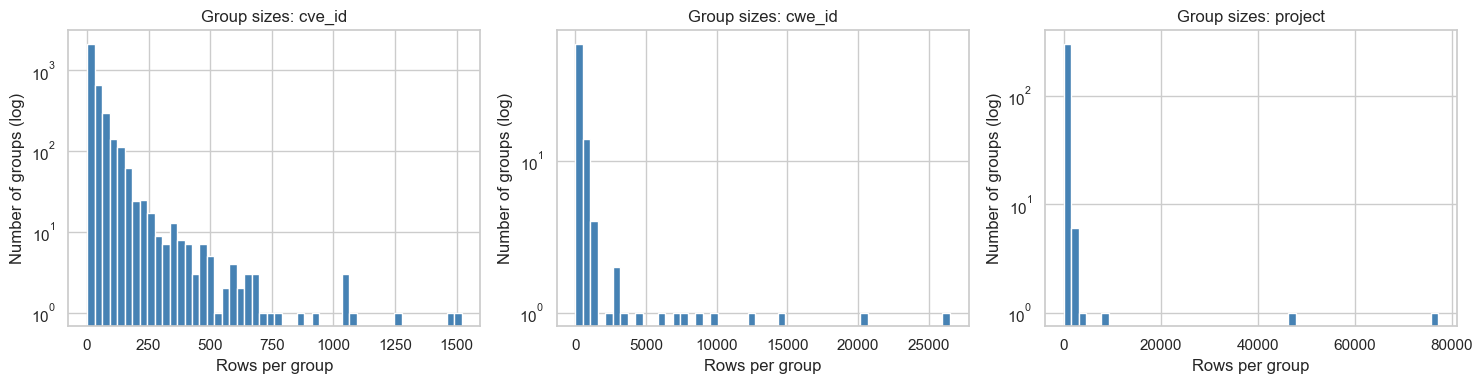

In [16]:
# 7.1b — Group-size distribution plots
plot_cols = [c for c in ["cve_id", "cwe_id", "project"] if _has(c)]
if plot_cols:
    fig, axes = plt.subplots(1, len(plot_cols), figsize=(5 * len(plot_cols), 4))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        sizes = df[col].value_counts().values
        ax.hist(sizes, bins=50, color="steelblue", edgecolor="white")
        ax.set_yscale("log")
        ax.set_title(f"Group sizes: {col}")
        ax.set_xlabel("Rows per group")
        ax.set_ylabel("Number of groups (log)")
    plt.tight_layout()
    plt.show()
else:
    print("No grouping columns available for plotting.")

In [17]:
# 7.1c — Duplicate code analysis and conflicting-label detection
if _has("func_before"):
    code_counts = df["func_before"].value_counts()
    n_dup_snippets = (code_counts > 1).sum()
    n_dup_rows = code_counts[code_counts > 1].sum()
    print(f"Exact duplicate analysis (func_before):")
    print(f"  Unique code snippets:       {len(code_counts):,}")
    print(f"  Snippets appearing >1 time: {n_dup_snippets:,}")
    print(f"  Rows involved in duplicates: {n_dup_rows:,} ({n_dup_rows/len(df)*100:.1f}%)")
    print(f"\n  Top 10 most repeated snippets (by occurrence count):")
    top_dups = code_counts.head(10).reset_index()
    top_dups.columns = ["snippet_hash", "count"]
    # show first 60 chars only as identifier
    top_dups["snippet_preview"] = top_dups["snippet_hash"].str[:60].str.replace("\n", " ")
    display(top_dups[["snippet_preview", "count"]])

    if _has("vul"):
        # check for identical code with conflicting labels
        code_labels = df.groupby("func_before")["vul"].agg(["min", "max"])
        conflicts = code_labels[code_labels["min"] != code_labels["max"]]
        print(f"\n  Conflicting labels (same code, different vul label): {len(conflicts):,} snippets")
        if len(conflicts) > 0:
            # show a few compact examples
            conflict_examples = df[df["func_before"].isin(conflicts.index[:3])].groupby("func_before").agg(
                n_rows=("vul", "count"),
                n_vul=("vul", "sum"),
                cves=("cve_id", lambda x: ", ".join(x.unique()[:3]))
            ).reset_index()
            conflict_examples["preview"] = conflict_examples["func_before"].str[:60].str.replace("\n", " ")
            print("  Example conflicts:")
            display(conflict_examples[["preview", "n_rows", "n_vul", "cves"]])
else:
    print("func_before column not found — skipping duplicate analysis.")

Exact duplicate analysis (func_before):
  Unique code snippets:       188,636
  Snippets appearing >1 time: 0
  Rows involved in duplicates: 0 (0.0%)

  Top 10 most repeated snippets (by occurrence count):


,snippet_preview,count
0,static bool check_rodc_critical_attribute(stru...,1
1,bool TabSpecificContentSettings::OnMessageRece...,1
2,bool TabSpecificContentSettings::IsContentBloc...,1
3,void TabSpecificContentSettings::NotifySiteDat...,1
4,void TabSpecificContentSettings::Observe( ...,1
5,void TabSpecificContentSettings::OnContentAcce...,1
6,void TabSpecificContentSettings::OnCookieChang...,1
7,void TabSpecificContentSettings::OnCookiesRead...,1
8,void TabSpecificContentSettings::OnFileSystemA...,1
9,void TabSpecificContentSettings::OnGeolocation...,1



  Conflicting labels (same code, different vul label): 0 snippets


In [18]:
# 7.1d — Conclusion
print("=" * 60)
print("  7.1 CONCLUSION")
print("=" * 60)
print("""
• Row-level random splitting is RISKY: large CVE groups (up to ~1,500 rows)
  mean the same CVE easily lands in both train and test.
• Duplicate code snippets add a second leakage vector: identical functions
  with different labels (or the same label) can appear across splits.
• Best grouping candidates for split boundaries (in order of strength):
  1. cve_id  — most fine-grained; prevents CVE-level memorisation
  2. commit_id — prevents commit-level leakage (same patch in multiple splits)
  3. project  — coarsest; prevents project-style leakage but may be too aggressive
""")

  7.1 CONCLUSION

• Row-level random splitting is RISKY: large CVE groups (up to ~1,500 rows)
  mean the same CVE easily lands in both train and test.
• Duplicate code snippets add a second leakage vector: identical functions
  with different labels (or the same label) can appear across splits.
• Best grouping candidates for split boundaries (in order of strength):
  1. cve_id  — most fine-grained; prevents CVE-level memorisation
  2. commit_id — prevents commit-level leakage (same patch in multiple splits)
  3. project  — coarsest; prevents project-style leakage but may be too aggressive



### 7.2 Label balance by group

**What this checks:** Whether CVEs / CWEs / projects are nearly pure (all-benign or all-vulnerable) or contain a mix of labels.

**Why it matters:** If most groups are pure, a group-based split could accidentally concentrate all vulnerable samples in one split. We need enough mixed-label groups to ensure every split has both classes.


  Label balance by cve_id  (3,539 groups)

Vulnerable ratio per group — summary:
count    3539.000000
mean        0.172374
std         0.246128
min         0.000000
25%         0.026316
50%         0.066667
75%         0.200000
max         1.000000

  All-benign groups: 255
  All-vulnerable groups: 178
  Mixed groups: 3,106


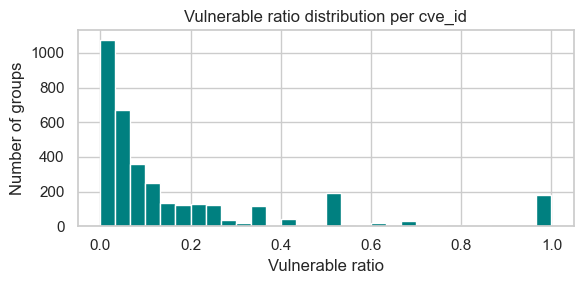


Top 20 cve_id groups by total sample count:


,cve_id,total,vulnerable,benign,vul_ratio
0,CVE-2016-5219,1520,12,1508,0.8%
1,CVE-2014-1713,1462,8,1454,0.5%
2,CVE-2011-2918,1259,74,1185,5.9%
3,CVE-2017-5120,1066,2,1064,0.2%
4,CVE-2012-2875,1057,28,1029,2.6%
5,CVE-2012-5148,1053,20,1033,1.9%
6,CVE-2013-7421,1049,1,1048,0.1%
7,CVE-2018-13006,931,6,925,0.6%
8,CVE-2017-9059,877,51,826,5.8%
9,CVE-2017-5019,768,7,761,0.9%



  Label balance by cwe_id  (91 groups)

Vulnerable ratio per group — summary:
count    91.000000
mean      0.125378
std       0.214178
min       0.000000
25%       0.039156
50%       0.056338
75%       0.085292
max       1.000000

  All-benign groups: 3
  All-vulnerable groups: 4
  Mixed groups: 84


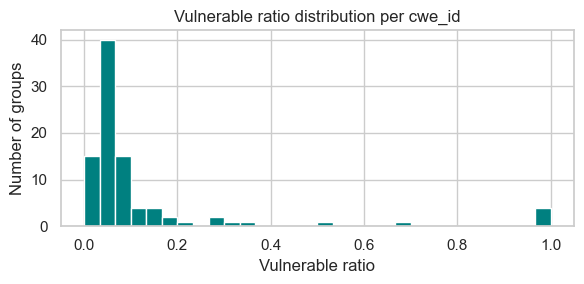


Top 20 cwe_id groups by total sample count:


,cwe_id,total,vulnerable,benign,vul_ratio
0,CWE-119,26497,2127,24370,8.0%
1,CWE-20,20501,1142,19359,5.6%
2,CWE-399,14806,736,14070,5.0%
3,CWE-264,12487,508,11979,4.1%
4,CWE-416,9780,330,9450,3.4%
5,CWE-200,8636,503,8133,5.8%
6,CWE-125,7717,625,7092,8.1%
7,CWE-189,6964,337,6627,4.8%
8,CWE-362,6073,278,5795,4.6%
9,CWE-476,4572,215,4357,4.7%



Top 20 CWEs ranked by vulnerable count:


,cwe_id,total,vulnerable,benign,vul_ratio
0,CWE-119,26497,2127,24370,8.0%
1,CWE-20,20501,1142,19359,5.6%
2,CWE-399,14806,736,14070,5.0%
3,CWE-125,7717,625,7092,8.1%
4,CWE-264,12487,508,11979,4.1%
5,CWE-200,8636,503,8133,5.8%
6,CWE-189,6964,337,6627,4.8%
7,CWE-416,9780,330,9450,3.4%
8,CWE-190,3671,307,3364,8.4%
9,CWE-362,6073,278,5795,4.6%



  Label balance by project  (310 groups)

Vulnerable ratio per group — summary:
count    310.000000
mean       0.112308
std        0.163433
min        0.000000
25%        0.031374
50%        0.064105
75%        0.125000
max        1.000000

  All-benign groups: 16
  All-vulnerable groups: 6
  Mixed groups: 288


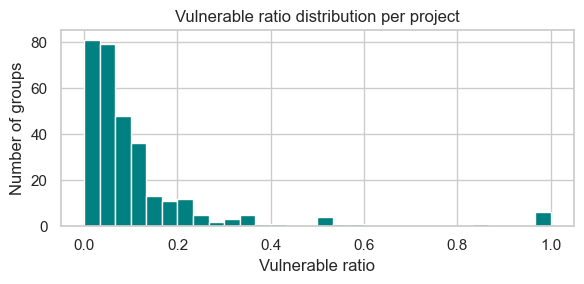


Top 20 project groups by total sample count:


,project,total,vulnerable,benign,vul_ratio
0,Chrome,77173,3939,73234,5.1%
1,linux,46855,1961,44894,4.2%
2,Android,8691,1277,7414,14.7%
3,qemu,3096,125,2971,4.0%
4,php,2709,136,2573,5.0%
5,ImageMagick,2520,338,2182,13.4%
6,savannah,2176,108,2068,5.0%
7,FFmpeg,1932,115,1817,6.0%
8,ghostscript,1867,86,1781,4.6%
9,openssl,1860,163,1697,8.8%


In [19]:
# 7.2a — Per-group label balance
if not _has("vul"):
    print("⏭ 'vul' column missing — skipping label balance analysis.")
else:
    for col in ["cve_id", "cwe_id", "project"]:
        bal = compute_group_label_balance(col)
        if bal is None:
            continue
        print(f"\n{'='*50}")
        print(f"  Label balance by {col}  ({len(bal):,} groups)")
        print(f"{'='*50}")
        print(f"\nVulnerable ratio per group — summary:")
        print(bal["vul_ratio"].describe().to_string())

        # Group purity counts
        all_benign = (bal["vul_ratio"] == 0).sum()
        all_vul = (bal["vul_ratio"] == 1).sum()
        mixed = len(bal) - all_benign - all_vul
        print(f"\n  All-benign groups: {all_benign:,}")
        print(f"  All-vulnerable groups: {all_vul:,}")
        print(f"  Mixed groups: {mixed:,}")

        # Histogram
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.hist(bal["vul_ratio"], bins=30, color="teal", edgecolor="white")
        ax.set_title(f"Vulnerable ratio distribution per {col}")
        ax.set_xlabel("Vulnerable ratio")
        ax.set_ylabel("Number of groups")
        plt.tight_layout()
        plt.show()

        # Top 20 by sample count
        top20 = bal.nlargest(20, "total")[
            [col, "total", "vulnerable", "benign", "vul_ratio"]
        ].reset_index(drop=True)
        top20["vul_ratio"] = top20["vul_ratio"].map("{:.1%}".format)
        print(f"\nTop 20 {col} groups by total sample count:")
        display(top20)

        # Extra table for CWE: ranked by vulnerable count
        if col == "cwe_id":
            top20_vul = bal.nlargest(20, "vulnerable")[
                ["cwe_id", "total", "vulnerable", "benign", "vul_ratio"]
            ].reset_index(drop=True)
            top20_vul["vul_ratio"] = top20_vul["vul_ratio"].map("{:.1%}".format)
            print(f"\nTop 20 CWEs ranked by vulnerable count:")
            display(top20_vul)

In [20]:
# 7.2b — Interpretation
print("=" * 60)
print("  7.2 INTERPRETATION")
print("=" * 60)
print("""
• CVE-level: Most CVE groups are heavily benign (median vul_ratio ~5-6%).
  Very few CVEs are all-vulnerable, but the distribution is extremely skewed.
  Splitting by CVE should still preserve both classes in each split because
  there are many mixed groups.
• CWE-level: All large CWEs are mixed, but some rare CWEs may be pure.
  CWE is too coarse for splitting (only 91 groups).
• Project-level: Similar to CVE — most projects are mixed with low vul ratio.
  Splitting by project is viable but very coarse.

→ CVE-level grouping has enough mixed structure to support balanced splitting.
→ CWE-level is too skewed (few groups) to be a primary split axis.
""")

  7.2 INTERPRETATION

• CVE-level: Most CVE groups are heavily benign (median vul_ratio ~5-6%).
  Very few CVEs are all-vulnerable, but the distribution is extremely skewed.
  Splitting by CVE should still preserve both classes in each split because
  there are many mixed groups.
• CWE-level: All large CWEs are mixed, but some rare CWEs may be pure.
  CWE is too coarse for splitting (only 91 groups).
• Project-level: Similar to CVE — most projects are mixed with low vul ratio.
  Splitting by project is viable but very coarse.

→ CVE-level grouping has enough mixed structure to support balanced splitting.
→ CWE-level is too skewed (few groups) to be a primary split axis.



### 7.3 Diversity diagnostics for candidate 1000-row sampling strategies

**What this checks:** Six candidate sampling policies are run side-by-side and compared on diversity, class balance, and concentration metrics.

**Why it matters:** A random 1,000-row sample from a 188K-row dataset with 3,500+ CVEs will likely over-represent a few dominant CVEs. We need to quantify how much each strategy improves diversity.

In [21]:
# 7.3a — Run all sampling strategies and build comparison table
strategies = {}
strategies["1_random"] = sample_random(df)
strategies["2_stratified_vul"] = sample_stratified_vul(df)

s = sample_capped_per_group(df, "cve_id", cap=5)
if s is not None:
    strategies["3_capped_CVE"] = s

s = sample_capped_per_group(df, "cwe_id", cap=50)
if s is not None:
    strategies["4_capped_CWE"] = s

s = sample_hierarchical(df)
if s is not None:
    strategies["5_hierarchical"] = s

s = sample_balanced_diversity(df)
if s is not None:
    strategies["6_balanced_div"] = s

# Compute diversity metrics
metrics = [evaluate_sample_diversity(v, k) for k, v in strategies.items()]
comparison = pd.DataFrame(metrics).set_index("strategy")

# Format for display
fmt_cols = {c: "{:.3f}" for c in comparison.columns if "ratio" in c or "len" in c.lower()}
display(comparison.style.format(fmt_cols, na_rep="—").set_caption("Sampling Strategy Comparison"))

/var/folders/p6/n0kd4w3d1bb32y0_kt5nnm2c0000gn/T/ipykernel_95404/4083869556.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df_in.groupby("vul", group_keys=False).apply(
/var/folders/p6/n0kd4w3d1bb32y0_kt5nnm2c0000gn/T/ipykernel_95404/4083869556.py:51: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  capped = df_in.groupby(group_col, group_keys=False).apply(
/var/folders/p6/n0kd4w3d1bb32y0_kt5nnm2c0000gn/T/i

,rows,vul_ratio,unique_cve_ids,median_per_cve_id,max_per_cve_id,unique_cwe_ids,median_per_cwe_id,max_per_cwe_id,unique_projects,median_per_project,max_per_project,median_char_len,p95_char_len
strategy,,,,,,,,,,,,,
1_random,1000,0.063,639,1.000000,12,51,4.000000,138,118,1.000000,406,397.000,3428.250
2_stratified_vul,999,0.057,636,1.000000,8,44,5.000000,117,114,1.000000,424,403.000,2640.600
3_capped_CVE,1000,0.117,901,1.000000,3,62,3.000000,197,151,1.000000,259,506.500,4974.750
4_capped_CWE,1000,0.080,403,1.000000,19,86,12.000000,21,102,3.000000,200,507.000,3937.300
5_hierarchical,1000,0.179,930,1.000000,10,21,10.000000,318,143,1.000000,226,665.500,9885.800
6_balanced_div,1000,0.500,872,1.000000,3,62,2.000000,146,137,1.000000,258,773.500,7946.000


/var/folders/p6/n0kd4w3d1bb32y0_kt5nnm2c0000gn/T/ipykernel_95404/1122692036.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
/var/folders/p6/n0kd4w3d1bb32y0_kt5nnm2c0000gn/T/ipykernel_95404/1122692036.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)


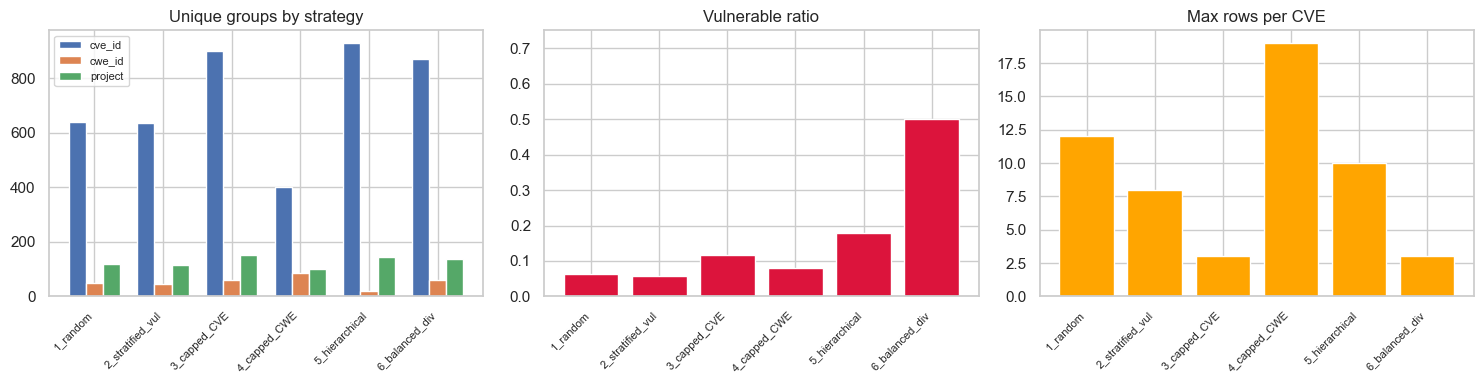

In [22]:
# 7.3b — Visual comparisons
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
names = list(strategies.keys())

# Unique CVEs/CWEs/projects
ax = axes[0]
for i, col in enumerate(["unique_cve_ids", "unique_cwe_ids", "unique_projects"]):
    if col in comparison.columns:
        vals = comparison[col].values
        x = np.arange(len(names))
        ax.bar(x + i * 0.25, vals, width=0.25, label=col.replace("unique_", "").replace("s", ""))
ax.set_xticks(np.arange(len(names)) + 0.25)
ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
ax.set_title("Unique groups by strategy")
ax.legend(fontsize=8)

# Vulnerable ratio
ax = axes[1]
if "vul_ratio" in comparison.columns:
    ax.bar(names, comparison["vul_ratio"].values, color="crimson")
    ax.set_title("Vulnerable ratio")
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, min(1, comparison["vul_ratio"].max() * 1.5))

# Max CVE concentration
ax = axes[2]
if "max_per_cve_id" in comparison.columns:
    ax.bar(names, comparison["max_per_cve_id"].values, color="orange")
    ax.set_title("Max rows per CVE")
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)

plt.tight_layout()
plt.show()

In [23]:
# 7.3c — Recommendation
print("=" * 60)
print("  7.3 RECOMMENDATION")
print("=" * 60)
print("""
Best candidates (examine table above for exact numbers):

1. **Balanced-diversity (6)**: Best class balance (~50/50 vul) with CVE cap
   preventing any single CVE from dominating. Highest unique CVE count.

2. **Capped-per-CVE (3)**: Good CVE diversity (cap=5 rows/CVE) while
   preserving the natural vul ratio. Simple to implement and explain.

→ If class balance is the priority: use balanced-diversity.
→ If preserving natural distribution is preferred: use capped-per-CVE.
""")

  7.3 RECOMMENDATION

Best candidates (examine table above for exact numbers):

1. **Balanced-diversity (6)**: Best class balance (~50/50 vul) with CVE cap
   preventing any single CVE from dominating. Highest unique CVE count.

2. **Capped-per-CVE (3)**: Good CVE diversity (cap=5 rows/CVE) while
   preserving the natural vul ratio. Simple to implement and explain.

→ If class balance is the priority: use balanced-diversity.
→ If preserving natural distribution is preferred: use capped-per-CVE.



### 7.4 Concentration and dominance analysis

**What this checks:** What fraction of a sample is captured by the top-1 / top-5 / top-10 CVEs and CWEs, plus the Herfindahl-Hirschman Index (HHI) as a single concentration number.

**Why it matters:** A sample dominated by a handful of CVEs effectively trains on those CVEs, not on "vulnerability detection" in general.

In [24]:
# 7.4 — Concentration metrics
def compute_concentration(sample_df, name):
    """Compute top-K share and HHI for CVE and CWE."""
    row = {"strategy": name}
    for col in ["cve_id", "cwe_id"]:
        if col not in sample_df.columns:
            continue
        counts = sample_df[col].value_counts()
        total = len(sample_df)
        shares = counts / total
        for k in [1, 5, 10]:
            row[f"top{k}_{col}_share"] = shares.head(k).sum()
        # HHI = sum of squared shares
        row[f"hhi_{col}"] = (shares ** 2).sum()
    return row

# Full dataset + all strategies
conc_rows = [compute_concentration(df, "full_dataset")]
for name, s_df in strategies.items():
    conc_rows.append(compute_concentration(s_df, name))

conc_df = pd.DataFrame(conc_rows).set_index("strategy")
display(conc_df.style.format("{:.4f}", na_rep="—").set_caption(
    "Concentration: top-K share and HHI (lower = more diverse)"))

print("\nInterpretation:")
print("• HHI close to 0 = very dispersed; HHI close to 1 = dominated by one group")
print("• Strategies with lowest HHI and lowest top-10 share are the most diverse.")

,top1_cve_id_share,top5_cve_id_share,top10_cve_id_share,hhi_cve_id,top1_cwe_id_share,top5_cwe_id_share,top10_cwe_id_share,hhi_cwe_id
strategy,,,,,,,,
full_dataset,0.0081,0.0337,0.0585,0.0011,0.1405,0.4457,0.6257,0.0531
1_random,0.0120,0.0460,0.0790,0.0021,0.1380,0.4340,0.6230,0.0523
2_stratified_vul,0.0080,0.0390,0.0691,0.0020,0.1171,0.4114,0.5986,0.0458
3_capped_CVE,0.0030,0.0110,0.0210,0.0012,0.1970,0.4980,0.6820,0.0733
4_capped_CWE,0.0190,0.0830,0.1500,0.0059,0.0210,0.1000,0.1890,0.0133
5_hierarchical,0.0100,0.0400,0.0590,0.0014,0.3180,0.8530,0.9160,0.1941
6_balanced_div,0.0030,0.0150,0.0300,0.0013,0.1460,0.4970,0.7030,0.0658



Interpretation:
• HHI close to 0 = very dispersed; HHI close to 1 = dominated by one group
• Strategies with lowest HHI and lowest top-10 share are the most diverse.


### 7.5 Split design diagnostics

**What this checks:** Simulates train/val/test splits (80/10/10) using different grouping units and checks for leakage, label coverage, and rare-CWE disappearance.

**Why it matters:** The split strategy determines whether evaluation metrics are trustworthy. Leaky splits inflate scores; overly aggressive splits may leave val/test with too few vulnerable samples.

In [25]:
# 7.5a — Simulate splits and compare
split_candidates = [None] + [c for c in ["cve_id", "project", "commit_id"] if _has(c)]
split_results = []

for group_col in split_candidates:
    splits, label = simulate_group_split(df, group_col)
    row = {"split_unit": label}
    for split_name, split_df in splits.items():
        row[f"{split_name}_rows"] = len(split_df)
        if _has("vul"):
            row[f"{split_name}_vul_ratio"] = f"{split_df['vul'].mean():.3f}"
        for col in ["cve_id", "cwe_id", "project"]:
            if _has(col):
                row[f"{split_name}_unique_{col}"] = split_df[col].nunique()

    # Leakage check
    if group_col and _has(group_col):
        train_groups = set(splits["train"][group_col].unique())
        val_groups = set(splits["val"][group_col].unique())
        test_groups = set(splits["test"][group_col].unique())
        overlap_tv = train_groups & val_groups
        overlap_tt = train_groups & test_groups
        overlap_vt = val_groups & test_groups
        row["leakage_train_val"] = len(overlap_tv)
        row["leakage_train_test"] = len(overlap_tt)
        row["leakage_val_test"] = len(overlap_vt)
    else:
        row["leakage_train_val"] = "N/A (row-random)"
        row["leakage_train_test"] = "N/A (row-random)"
        row["leakage_val_test"] = "N/A (row-random)"

    # Rare CWE disappearance
    if _has("cwe_id"):
        all_cwes = set(df["cwe_id"].unique())
        val_cwes = set(splits["val"]["cwe_id"].unique())
        test_cwes = set(splits["test"]["cwe_id"].unique())
        row["cwes_missing_from_val"] = len(all_cwes - val_cwes)
        row["cwes_missing_from_test"] = len(all_cwes - test_cwes)

    split_results.append(row)

split_comparison = pd.DataFrame(split_results)
display(split_comparison.set_index("split_unit").T)

split_unit,row-random,group-by-cve_id,group-by-project,group-by-commit_id
train_rows,150908,148033,176175,152986
train_vul_ratio,0.058,0.059,0.058,0.056
train_unique_cve_id,3495,2831,3076,2863
train_unique_cwe_id,90,84,88,88
train_unique_project,309,282,248,278
val_rows,18863,21382,8546,19319
val_vul_ratio,0.057,0.052,0.068,0.070
val_unique_cve_id,2657,354,381,388
val_unique_cwe_id,84,45,37,44
val_unique_project,271,81,31,77


In [26]:
# 7.5b — Split comparison summary
print("=" * 60)
print("  7.5 SPLIT COMPARISON SUMMARY")
print("=" * 60)
print("""
• Row-random: No leakage guarantees. Same CVE/commit/code can appear in
  train AND test. Scores will be inflated.

• Group-by-CVE: Zero CVE overlap across splits. Some rare CWEs may be
  absent from val/test (check counts above). Best leakage prevention
  at a practical granularity.

• Group-by-project: Zero project overlap, but very coarse — a few large
  projects may dominate one split, causing uneven label distributions.

• Group-by-commit: Zero commit overlap. Finer than project, coarser than
  CVE. Good middle ground if commit_id is available.

TRADE-OFF: Stricter group splits (project) lose more CWE coverage in
val/test. CVE-level splitting is the best balance of leakage prevention
and label coverage.
""")

  7.5 SPLIT COMPARISON SUMMARY

• Row-random: No leakage guarantees. Same CVE/commit/code can appear in
  train AND test. Scores will be inflated.

• Group-by-CVE: Zero CVE overlap across splits. Some rare CWEs may be
  absent from val/test (check counts above). Best leakage prevention
  at a practical granularity.

• Group-by-project: Zero project overlap, but very coarse — a few large
  projects may dominate one split, causing uneven label distributions.

• Group-by-commit: Zero commit overlap. Finer than project, coarser than
  CVE. Good middle ground if commit_id is available.

TRADE-OFF: Stricter group splits (project) lose more CWE coverage in
val/test. CVE-level splitting is the best balance of leakage prevention
and label coverage.



### 7.6 Outlier and truncation-relevant diagnostics

**What this checks:** Code length percentiles, distributions clipped at the 95th percentile, and the longest samples — to inform truncation thresholds for graph construction and tokenisation.

**Why it matters:** A handful of extremely long functions can dominate memory, slow graph construction, and distort average statistics. Knowing where to clip helps set practical limits.

Code length percentiles:


,code_char_len,code_line_count,code_token_count
50.0%,395.000,14.0,33.000
75.0%,873.000,31.0,80.000
90.0%,1880.000,65.0,183.000
95.0%,3063.250,102.0,301.000
99.0%,7924.250,251.0,783.000
99.5%,12227.275,374.0,1123.825


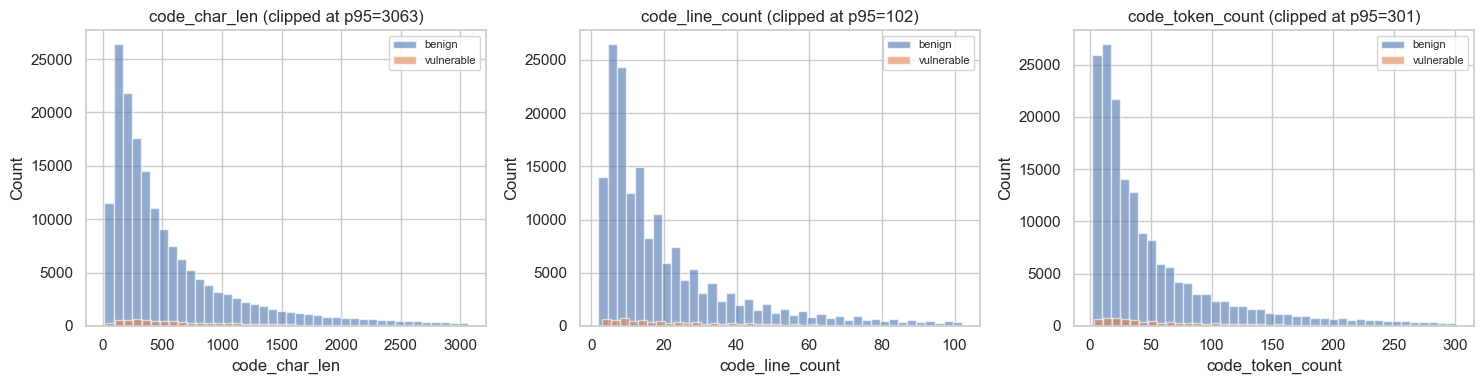


Top 20 longest samples (by char length):


,cve_id,cwe_id,project,file_name,vul,code_char_len,code_line_count,code_token_count
0,CVE-2017-12427,CWE-772,ImageMagick,coders/msl.c,0,240969,6820,12166
1,CVE-2016-10068,CWE-20,ImageMagick,coders/msl.c,1,234459,6676,12047
2,CVE-2018-17942,CWE-119,gnulib,lib/vasnprintf.c,0,167795,3822,12425
3,CVE-2017-1000211,CWE-416,lynx-snapshots,src/HTML.c,0,142630,4679,15441
4,CVE-2017-8284,CWE-94,qemu,target/i386/translate.c,1,137986,3850,12149
5,CVE-2019-10664,CWE-89,domoticz,main/WebServer.cpp,0,128416,3822,12889
6,CVE-2019-10664,CWE-89,domoticz,main/WebServer.cpp,0,121065,3981,11576
7,CVE-2017-11522,CWE-476,ImageMagick,coders/png.c,1,114340,3574,8326
8,CVE-2017-13142,CWE-754,ImageMagick,coders/png.c,0,114259,3599,8368
9,CVE-2018-16749,CWE-617,ImageMagick6,coders/png.c,0,113858,3586,8334



Length stats by vulnerability label:


vul                                 0              1
code_char_len    count  177736.000000   10900.000000
                 mean      807.978440    2581.138349
                 std      2046.433796    6110.459426
                 min        14.000000      28.000000
                 25%       187.000000     419.750000
                 50%       378.000000     982.000000
                 75%       815.000000    2303.250000
                 max    240969.000000  234459.000000
code_line_count  count  177736.000000   10900.000000
                 mean       27.699436      83.678165
                 std        61.417366     189.588639
                 min         2.000000       3.000000
                 25%         7.000000      14.000000
                 50%        14.000000      33.500000
                 75%        29.000000      79.000000
                 max      6820.000000    6676.000000
code_token_count count  177736.000000   10900.000000
                 mean       74.415594     231.374954
                 std       174.392975     507.596035
                 min         2.000000       3.000000
                 25%        14.000000      32.000000
                 50%        32.000000      84.000000
                 75%        75.000000     223.000000
                 max     15441.000000   12149.000000

In [27]:
# 7.6a — Length percentiles and histograms
length_cols = [c for c in ["code_char_len", "code_line_count", "code_token_count"] if _has(c)]

if length_cols:
    # Percentile table
    pctiles = [0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
    pct_table = df[length_cols].quantile(pctiles)
    pct_table.index = [f"{p:.1%}" for p in pctiles]
    print("Code length percentiles:")
    display(pct_table)

    # Clipped histograms (up to 95th percentile)
    fig, axes = plt.subplots(1, len(length_cols), figsize=(5 * len(length_cols), 4))
    if len(length_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, length_cols):
        p95 = df[col].quantile(0.95)
        clipped = df[col][df[col] <= p95]
        if _has("vul"):
            for label in [0, 1]:
                name = "vulnerable" if label == 1 else "benign"
                subset = df[df["vul"] == label][col]
                ax.hist(subset[subset <= p95], bins=40, alpha=0.6, label=name)
            ax.legend(fontsize=8)
        else:
            ax.hist(clipped, bins=40, color="steelblue", edgecolor="white")
        ax.set_title(f"{col} (clipped at p95={p95:.0f})")
        ax.set_xlabel(col)
        ax.set_ylabel("Count")
    plt.tight_layout()
    plt.show()

    # Top 20 longest samples (metadata only)
    if _has("code_char_len"):
        meta_cols = [c for c in ["cve_id", "cwe_id", "project", "file_name", "vul",
                                  "code_char_len", "code_line_count", "code_token_count"]
                     if _has(c)]
        top20_long = df.nlargest(20, "code_char_len")[meta_cols].reset_index(drop=True)
        print("\nTop 20 longest samples (by char length):")
        display(top20_long)

    # Length stats by vul
    if _has("vul"):
        print("\nLength stats by vulnerability label:")
        display(df.groupby("vul")[length_cols].describe().T)
else:
    print("No code length columns found — skipping outlier analysis.")

In [28]:
# 7.6b — Outlier note
print("=" * 60)
print("  7.6 OUTLIER NOTE")
print("=" * 60)
print("""
• The top 1% of functions are dramatically longer than the median.
  These outliers inflate mean statistics and will be expensive for
  graph construction (Joern parsing) and tokenisation.
• Consider capping at the 95th percentile for graph building, or
  applying length-aware sampling to exclude extreme outliers.
• Vulnerable samples may have slightly different length distributions
  than benign ones — check the by-vul breakdown above.
""")

  7.6 OUTLIER NOTE

• The top 1% of functions are dramatically longer than the median.
  These outliers inflate mean statistics and will be expensive for
  graph construction (Joern parsing) and tokenisation.
• Consider capping at the 95th percentile for graph building, or
  applying length-aware sampling to exclude extreme outliers.
• Vulnerable samples may have slightly different length distributions
  than benign ones — check the by-vul breakdown above.



### 7.7 Final recommendation

**Summary of findings and concrete next steps for sampling and splitting.**

In [29]:
# 7.7 — Final recommendation
print("=" * 70)
print("  SAMPLING & SPLIT DESIGN — FINAL RECOMMENDATIONS")
print("=" * 70)
print("""
1. MAIN LEAKAGE RISK
   The same CVE (and often the same commit or identical code) appears in
   many rows. A row-level random split will leak CVE-specific patterns
   from train into val/test, inflating evaluation scores.

2. WHY PURE RANDOM 1000-ROW SAMPLING IS A BAD DEFAULT
   The dataset is dominated by a few large CVEs (top CVE has ~1,500 rows).
   A random 1000-row sample will over-represent these CVEs and under-
   represent the long tail. Class imbalance (~5.8% vul) is preserved but
   CVE/CWE diversity is poor.

3. RECOMMENDED SAMPLING STRATEGY
   Use capped-per-CVE sampling (cap=5 rows/CVE) combined with vul
   stratification. This ensures:
   - No single CVE dominates the sample
   - CVE and CWE diversity is maximised
   - Class ratio can be controlled
   Alternative: balanced-diversity sampler if 50/50 class balance is needed.

4. RECOMMENDED SPLIT STRATEGY
   Split by CVE (GroupKFold on cve_id) rather than by row. This:
   - Guarantees zero CVE overlap between train/val/test
   - Preserves reasonable label balance in each split
   - May lose a few rare CWEs from val/test (acceptable trade-off)

5. FOLLOW-UP CHECKS BEFORE BUILDING THE GRAPH DATASET
   - Verify that the chosen sample passes a duplicate-code check
   - Confirm val/test CWE coverage after CVE-based splitting
   - Set a code length cap (e.g., 95th percentile) to exclude outliers
     that would be expensive for Joern parsing
   - Re-run this EDA on the final 1000-row sample to confirm metrics
""")

print("-" * 70)
print("  RECOMMENDED NEXT STEP")
print("-" * 70)
print("""
Sample 1000 rows using capped-per-CVE (cap ≤ 5 rows per CVE) with vul
stratification to preserve class ratio. Split by cve_id (80/10/10) to
prevent leakage. Cap code length at the 95th percentile before graph
construction. Validate the final sample by re-running diversity and
concentration diagnostics.
""")

  SAMPLING & SPLIT DESIGN — FINAL RECOMMENDATIONS

1. MAIN LEAKAGE RISK
   The same CVE (and often the same commit or identical code) appears in
   many rows. A row-level random split will leak CVE-specific patterns
   from train into val/test, inflating evaluation scores.

2. WHY PURE RANDOM 1000-ROW SAMPLING IS A BAD DEFAULT
   The dataset is dominated by a few large CVEs (top CVE has ~1,500 rows).
   A random 1000-row sample will over-represent these CVEs and under-
   represent the long tail. Class imbalance (~5.8% vul) is preserved but
   CVE/CWE diversity is poor.

3. RECOMMENDED SAMPLING STRATEGY
   Use capped-per-CVE sampling (cap=5 rows/CVE) combined with vul
   stratification. This ensures:
   - No single CVE dominates the sample
   - CVE and CWE diversity is maximised
   - Class ratio can be controlled
   Alternative: balanced-diversity sampler if 50/50 class balance is needed.

4. RECOMMENDED SPLIT STRATEGY
   Split by CVE (GroupKFold on cve_id) rather than by row. This:
  